In [1]:
using LatticeDiracOperators
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2



NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3


const pes =  (2, 2, 2, 2)
const cuda = true
const numtrj_in = 2 # the number of operations to take average of performance
const MDsteps_in = 0 # dummy
PEs = pes
U= Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot",cuda=true,blocks=PEs)
# U= Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")

Ug = load("typical_gauge.jld2", "U")
substitute_U!(U,Ug)
# substitute_U!(U,U1)


x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)



params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.16
params["faster version"] = true
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3

D = Dirac_operator(U,x,params)
Ddag = DdagD_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=sqrt(norm2(y))
target=x/den
input=y/den

a=1


[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018] 
┌ Info: Skipping precompilation due to precompilable error. Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Threads backend loaded with 1 threads


1

In [2]:
PtcRayleighQuotient=PtcRayleighQuotient_Layer(D)
a

1

In [3]:
dl=DenseLinearLayer(1,25,true)
dl1=DenseLinearLayer(2,2,true)
a

1

In [4]:
P=Vector{Paths}(undef,9)
for i in 1:9
    if i<=5
        P[i]=Paths([[i-1]])
    else
        P[i]=Paths([[-(i-5)]])
    end
end
dirs = [1, 2, 3, 4, -1, -2, -3, -4]

max_len = 4                  # 만들고 싶은 최대 길이
lengths = Int[]

L = 2                          # 2^0 = 1도 포함하고 싶으면 1부터,
while L <= max_len             # 2부터만이면 L = 2로 시작
    push!(lengths, L)
    L *= 2
end

for d in dirs
    for L in lengths           # L = 1,2,4,8,...(max_len 이하)
        path_vec = fill(d, L)  # [d,d,...,d] (길이 L)
        push!(P, Paths([path_vec]))
    end
end
# P1=Vector{Paths}(undef, 25)
# for i in 1:25
#     P1[i]=Paths([[0]])
# end



In [5]:
i=10
pl=length(P)
PT=PTLayer(P,U,pl)
PT1=PTLayer(P,U,pl)
PT2=PTLayer(P,U,pl)
PT3=PTLayer(P,U,pl)
PT4=PTLayer(P,U,pl)
PT5=PTLayer(P,U,pl)
PT6=PTLayer(P,U,pl)
PT7=PTLayer(P,U,pl)
PT8=PTLayer(P,U,1)
PT9 = PTLayer(P, U, pl)
PT10=PTLayer(P,U,pl)
PT.W=i*PT.W
PT1.W=i*PT1.W
PT2.W=i*PT2.W
PT3.W=i*PT3.W
PT4.W=i*PT4.W
PT5.W=i*PT5.W
PT6.W=i*PT6.W
PT7.W=i*PT7.W
PT8.W=i*PT8.W
PT9.W=i*PT9.W
PT10.W=i*PT10.W
fe=fermionfield_Layer(x,1)
a

1

In [6]:
or=Orthogonal_Layer(0.0)

Orthogonal_Layer(0.0, Identity())

In [7]:
# loss=PtcRayleighQuotient+or
Ritz=Ritz_Layer(D)
Norm=NormLayer()

a

1

In [8]:
opt=Adam()
opt.α=0.1

0.1

In [9]:
U1= Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot",cuda=true,blocks=PEs)
Ug=load("C:/Users/_s2220186/Desktop/Julia/gauge/config_1.jld2", "U")
substitute_U!(U1,Ug)
U2= Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot",cuda=true,blocks=PEs)
Ug=load("C:/Users/_s2220186/Desktop/Julia/gauge/config_2.jld2", "U")
substitute_U!(U2,Ug);

In [10]:
M1=load("C:/Users/_s2220186/Desktop/multilowmode/gramschmitzmodel/8PTlayerRitz(mass016)($(8500)epoch)(i=10)M1.jld2","layers");

In [11]:
V=[]
function exchangeU( M, U, para)
    depth=length(M)
    for i in 1:depth
        if M[i] isa PTLayer
            M[i].U= U
        end 
    end
    if M[end] isa Ritz_Layer
        D= Dirac_operator(U,x,para)
        M[end].D=D
    end
end 

exchangeU (generic function with 1 method)

In [12]:
exchangeU(M1,U,params)
V1=(M1[1:end-1](U));
exchangeU(M1,U1,params)
V2=(M1[1:end-1](U1));
exchangeU(M1,U2,params)
V3=(M1[1:end-1](U2));
V=[V1,V2,V3];

In [13]:
gram=GramSchmidt_Layer(V1);
# layers=[fe,dl,PT1,PT2,PT3,PT4,PT5,PT6,PT7,PT8,gram,Norm,Ritz];
layers=load("C:/Users/_s2220186/Desktop/multilowmode/gramschmitzmodel/8PTlayerRitz(mass016)($(4200)epoch)(i=10)M2.jld2","layers");
layers[11]=gram;

Epoch: 1, Loss: 0.0005056677659283984 + 0.0im
Epoch: 2, Loss: 0.007538751995455141 + 0.0im
Epoch: 3, Loss: 0.0048126761412425985 + 0.0im
Epoch: 4, Loss: 0.0005526435341666755 + 0.0im
Epoch: 5, Loss: 0.007700627096938985 + 0.0im
Epoch: 6, Loss: 0.004845224371736709 + 0.0im
Epoch: 7, Loss: 0.0006840289545727924 + 0.0im
Epoch: 8, Loss: 0.009348175987155807 + 0.0im
Epoch: 9, Loss: 0.005092327082259255 + 0.0im
Epoch: 10, Loss: 0.0010316213335131719 + 0.0im
Epoch: 11, Loss: 0.00848016275909598 + 0.0im
Epoch: 12, Loss: 0.005327775473291806 + 0.0im
Epoch: 13, Loss: 0.0011321997512573538 + 0.0im
Epoch: 14, Loss: 0.008386929823636742 + 0.0im
Epoch: 15, Loss: 0.0050378407765326065 + 0.0im
Epoch: 16, Loss: 0.0010889869890979473 + 0.0im
Epoch: 17, Loss: 0.008124404621509249 + 0.0im
Epoch: 18, Loss: 0.005034830848721047 + 0.0im
Epoch: 19, Loss: 0.0011159532993688717 + 0.0im
Epoch: 20, Loss: 0.007866712521121625 + 0.0im
Epoch: 21, Loss: 0.004861834367083627 + 0.0im
Epoch: 22, Loss: 0.0009868110208256

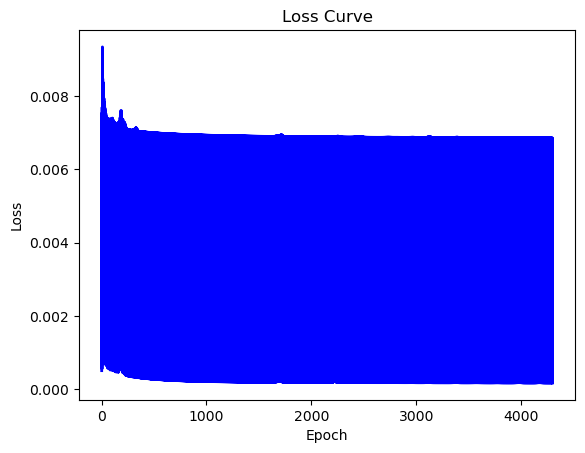

In [14]:
@time train(opt,layers,[U,U1,U2],V,params,epochs=4300)

In [15]:
save("8PTlayerRitz(mass016)($(8500)epoch)(i=10)M2.jld2", "layers", layers)